# Categorising inter-syllable gaps from prosody

**Occurrence** = the gap between two consecutive syllables of a sentence (not a pause: just the position between them).

**Vector** = binary prosodic features of the gap:
* acoustic features of the syllable before and the syllable after (the word notebook's `ACOUSTIC_MEASURES`, duration included);
* perceptual features of the tokens these syllables belong to: prominence, placed on the syllable it describes (ProminenceFinal → last syllable of the token, ProminenceInitial → first), and Begin / End of Foot, Group, Package and Period.

We cluster the vectors, then compare the clusters with two syntactic descriptions of each gap, used **only for evaluation**:
* **constituency** — is the gap inside a word, inside a phrase or between phrases, and which ones (NP, VP, PP, AP, S…)?
* **dependency** — which dependencies cross above the gap (the flux), and which one is innermost?

The treebank is read directly (no grew / grex), so each step can be checked here.

In [30]:
from collections import Counter, defaultdict
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import normalize
from sklearn.metrics import (adjusted_mutual_info_score, adjusted_rand_score,
                             balanced_accuracy_score,
                             homogeneity_completeness_v_measure, silhouette_score)
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.tree import DecisionTreeClassifier, export_text

TREEBANK_PATH = "/Users/madalina/Documents/PHD/code/data/SUD_French-Rhapsodie/prosody_no_punct.conllu"

# ── Which features describe a gap ─────────────────────────────────────────
#   "all"        : acoustic + perceptual
#   "acoustic"   : only signal-derived syllable measures
#   "perceptual" : only prominence and prosodic-unit Begin/End
FEATURE_SET = "all"

ACOUSTIC_MEASURES = ("Duration", "AvgHeightGlo", "PitchRangeGlo", "SlopeGlo",
                     "SemitonesFromUtteranceMean")
UNIT_LEVELS = ("Foot", "Group", "Package", "Period")

# Where the token's Begin/End go:
#   "token"    : both syllables get the Begin/End of the token they belong to.
#                Inside a word, both sides then carry the same token's values,
#                which partly reveals "same word".
#   "syllable" : Begin only on the token's first syllable, End only on its last
#                (the same choice as for prominence).
TOKEN_ANCHOR = "syllable"

MIN_FEATURE_OCC = 10          # a feature seen fewer times is noise (as in the word notebook)
EXCLUDE_PILES = False          # drop gaps touching a disfluent pile
PILE_RELS = {"repair", "conj:dicto", "conj:reform"}

K_RANGE = range(2, 16)        # numbers of clusters tried in Step 3
K = 6                         # number of clusters used from Step 4 on: set it after Step 3
TREE_DEPTH = 4                # depth of the decision trees in Step 8
SEED = 0

## Step 0 — read the treebank
Syllables are the `X.n` subnodes. Their HEAD column lists the token(s) they belong to (two for a fused syllable such as [se] in *c'est*). Syllables are kept in file order: in about 20 sentences the time stamps contradict the token order, which looks like alignment errors.

In [31]:
def _misc(field):
    return dict(kv.split("=", 1) for kv in field.split("|") if "=" in kv) if field != "_" else {}


def read_sentences(path):
    """One dict per sentence with prosodic annotation:
    tokens    {id: dict(form, upos, head, rel, misc)}
    syllables [dict(id, toks, misc), ...] in file order."""
    def parse(meta, lines):
        tokens, syllables = {}, []
        for c in lines:
            if "-" in c[0]:
                continue
            m = _misc(c[9])
            if "." in c[0]:
                toks = [int(t) for t in c[6].split("|") if t.isdigit()]
                if toks:
                    syllables.append(dict(id=c[0], toks=toks, misc=m))
            else:
                tokens[int(c[0])] = dict(form=c[1], upos=c[3], rel=c[7], misc=m,
                                         head=int(c[6]) if c[6].isdigit() else 0)
        # first and last syllable of each token
        first, last = {}, {}
        for k, sy in enumerate(syllables):
            for t in sy["toks"]:
                first.setdefault(t, k)
                last[t] = k
        return dict(sent_id=meta.get("sent_id"), text=meta.get("text", ""),
                    tokens=tokens, syllables=syllables, first=first, last=last)

    meta, lines = {}, []
    with open(path, encoding="utf8") as f:
        for line in f:
            line = line.rstrip("\n")
            if not line:
                if lines and meta.get("prosodic_annotation") == "yes":
                    yield parse(meta, lines)
                meta, lines = {}, []
            elif line.startswith("#"):
                if " = " in line:
                    k, v = line[2:].split(" = ", 1)
                    meta[k] = v
            else:
                lines.append(line.split("\t"))
    if lines and meta.get("prosodic_annotation") == "yes":
        yield parse(meta, lines)


SENTS = list(read_sentences(TREEBANK_PATH))
print(f"{len(SENTS)} sentences with prosodic annotation, "
      f"{sum(len(s['syllables']) for s in SENTS)} syllables")

2979 sentences with prosodic annotation, 43827 syllables


## Step 0b — the gaps
A gap sits between syllable *k* and syllable *k*+1. **L** is the token of the syllable before (the last one, for a fused syllable) and **R** the token of the syllable after. L = R: the gap is inside a word. R = L+1: the gap is a word boundary. Anything else (a token with no syllable in between) is skipped.

In [32]:
def pile_words(tokens):
    """Words in a disfluent pile: they bear a pile relation, or govern one (as in the word notebook)."""
    out = set()
    for i, t in tokens.items():
        if t["rel"] in PILE_RELS:
            out |= {i, t["head"]}
    return out


GAPS, skipped = [], Counter()
for s in SENTS:
    tok, syl = s["tokens"], s["syllables"]
    piles = pile_words(tok) if EXCLUDE_PILES else set()
    for k in range(len(syl) - 1):
        L, R = max(syl[k]["toks"]), min(syl[k + 1]["toks"])
        if L not in tok or R not in tok:
            skipped["syllable without token"] += 1
        elif L != R and R != L + 1:
            skipped["not adjacent tokens"] += 1
        elif L in piles or R in piles:
            skipped["disfluent pile"] += 1
        else:
            GAPS.append(dict(sent=s, k=k, L=L, R=R,
                             gap_type="word-internal" if L == R else "word boundary"))

print(f"{len(GAPS)} gaps kept | skipped: {dict(skipped)}")
print(Counter(g["gap_type"] for g in GAPS))

40661 gaps kept | skipped: {'not adjacent tokens': 206}
Counter({'word boundary': 26309, 'word-internal': 14352})


## Step 1 — one binary vector per gap
Continuous measures are cut into three corpus-wide quantile bins, with the 0.0 sentinel treated as missing, as in the word notebook. Feature names start with `before:` or `after:`.

In [33]:
BIN_LABELS = {
    "SemitonesFromUtteranceMean": ["F0_low", "F0_mid", "F0_high"],
    "Duration":                   ["Dur_short", "Dur_mid", "Dur_long"],
}
PROMINENCE_RANK = {"Weak": 1, "Strong": 2}       # 0, Pause and Overlap are not prominences


def _number(value):
    """Float, or None for missing values and the 0.0 sentinel."""
    try:
        v = float(value)
    except (TypeError, ValueError):
        return None
    return None if v == 0.0 else v


thresholds = {}
for name in BIN_LABELS:
    vals = np.array([v for s in SENTS for sy in s["syllables"]
                     if (v := _number(sy["misc"].get(name))) is not None])
    thresholds[name] = np.quantile(vals, [1 / 3, 2 / 3])
    lab = BIN_LABELS[name]
    print(f"  {name}: ≤{thresholds[name][0]:.2f} → {lab[0]} | ≤{thresholds[name][1]:.2f} → {lab[1]} | above → {lab[2]}")


def acoustic(sy):
    """Acoustic features of one syllable."""
    out = []
    for name in ACOUSTIC_MEASURES:
        v = sy["misc"].get(name)
        if name in BIN_LABELS:
            x = _number(v)
            if x is not None:
                out.append(BIN_LABELS[name][int(np.searchsorted(thresholds[name], x))])
        elif v not in (None, "X"):
            out.append(f"{name}={v}")
    return out


def prominence(s, k):
    """ProminenceFinal if syllable k is the last syllable of its token, ProminenceInitial
    if it is the first one; for a one-syllable token, the stronger of the two."""
    best = None
    for t in s["syllables"][k]["toks"]:
        if t not in s["tokens"]:
            continue
        m = s["tokens"][t]["misc"]
        vals = ([m.get("ProminenceFinal")] if s["last"][t] == k else []) + \
               ([m.get("ProminenceInitial")] if s["first"][t] == k else [])
        for v in vals:
            if v in PROMINENCE_RANK and (best is None or PROMINENCE_RANK[v] > PROMINENCE_RANK[best]):
                best = v
    return best


def unit_position(value):
    """Begin / In / Last / Unique. Period values carry * and - markers (e.g. '*I*'), which we strip."""
    return {"B": "Begin", "I": "In", "L": "Last", "U": "Unique"}.get((value or "").strip("*-")[:1])


def unit_features(s, k, t):
    """Begin / End of each prosodic unit for token t, seen from syllable k."""
    m, out = s["tokens"][t]["misc"], []
    for level in UNIT_LEVELS:
        pos = unit_position(m.get(level))
        begin, end = pos in ("Begin", "Unique"), pos in ("Last", "Unique")
        if TOKEN_ANCHOR == "syllable":
            begin, end = begin and s["first"][t] == k, end and s["last"][t] == k
        out += [f"{level}=Begin"] * begin + [f"{level}=End"] * end
    return out


def gap_features(g):
    s, k, feats = g["sent"], g["k"], []
    for side, kk, t in (("before", k, g["L"]), ("after", k + 1, g["R"])):
        if FEATURE_SET in ("all", "acoustic"):
            feats += [f"{side}:{f}" for f in acoustic(s["syllables"][kk])]
        if FEATURE_SET in ("all", "perceptual"):
            p = prominence(s, kk)
            feats += [f"{side}:Prominence={p}"] if p else []
            feats += [f"{side}:{f}" for f in unit_features(s, kk, t)]
    return feats


GAP_FEATS = [gap_features(g) for g in GAPS]
feat_counts = Counter(f for fs in GAP_FEATS for f in set(fs))
kept = sorted(f for f, n in feat_counts.items() if n >= MIN_FEATURE_OCC)
idx2feature = dict(enumerate(kept))
feature2idx = {f: i for i, f in idx2feature.items()}

# GAP_M[i, j] = 1 if gap i has feature j
GAP_M = np.zeros((len(GAPS), len(kept)), dtype=np.float32)
for a, fs in enumerate(GAP_FEATS):
    for f in fs:
        j = feature2idx.get(f)
        if j is not None:
            GAP_M[a, j] = 1

# a gap with no feature at all cannot be placed: drop it
has_feats = GAP_M.sum(1) > 0
GAPS = [g for g, keep in zip(GAPS, has_feats) if keep]
GAP_M = GAP_M[has_feats]
print(f"{GAP_M.shape[0]} gaps × {GAP_M.shape[1]} features "
      f"({(~has_feats).sum()} gaps without features dropped); "
      f"{GAP_M.sum(1).mean():.1f} features per gap on average")
print(", ".join(kept))

  SemitonesFromUtteranceMean: ≤-1.25 → F0_low | ≤0.59 → F0_mid | above → F0_high
  Duration: ≤131.00 → Dur_short | ≤199.00 → Dur_mid | above → Dur_long
40361 gaps × 50 features (300 gaps without features dropped); 13.7 features per gap on average
after:AvgHeightGlo=H, after:AvgHeightGlo=L, after:AvgHeightGlo=M, after:Dur_long, after:Dur_mid, after:Dur_short, after:F0_high, after:F0_low, after:F0_mid, after:Foot=Begin, after:Foot=End, after:Group=Begin, after:Group=End, after:Package=Begin, after:Package=End, after:Period=Begin, after:Period=End, after:PitchRangeGlo=H, after:PitchRangeGlo=L, after:PitchRangeGlo=M, after:Prominence=Strong, after:Prominence=Weak, after:SlopeGlo=Fall, after:SlopeGlo=Flat, after:SlopeGlo=Rise, before:AvgHeightGlo=H, before:AvgHeightGlo=L, before:AvgHeightGlo=M, before:Dur_long, before:Dur_mid, before:Dur_short, before:F0_high, before:F0_low, before:F0_mid, before:Foot=Begin, before:Foot=End, before:Group=Begin, before:Group=End, before:Package=Begin, before

In [34]:
idx2feature

{0: 'after:AvgHeightGlo=H',
 1: 'after:AvgHeightGlo=L',
 2: 'after:AvgHeightGlo=M',
 3: 'after:Dur_long',
 4: 'after:Dur_mid',
 5: 'after:Dur_short',
 6: 'after:F0_high',
 7: 'after:F0_low',
 8: 'after:F0_mid',
 9: 'after:Foot=Begin',
 10: 'after:Foot=End',
 11: 'after:Group=Begin',
 12: 'after:Group=End',
 13: 'after:Package=Begin',
 14: 'after:Package=End',
 15: 'after:Period=Begin',
 16: 'after:Period=End',
 17: 'after:PitchRangeGlo=H',
 18: 'after:PitchRangeGlo=L',
 19: 'after:PitchRangeGlo=M',
 20: 'after:Prominence=Strong',
 21: 'after:Prominence=Weak',
 22: 'after:SlopeGlo=Fall',
 23: 'after:SlopeGlo=Flat',
 24: 'after:SlopeGlo=Rise',
 25: 'before:AvgHeightGlo=H',
 26: 'before:AvgHeightGlo=L',
 27: 'before:AvgHeightGlo=M',
 28: 'before:Dur_long',
 29: 'before:Dur_mid',
 30: 'before:Dur_short',
 31: 'before:F0_high',
 32: 'before:F0_low',
 33: 'before:F0_mid',
 34: 'before:Foot=Begin',
 35: 'before:Foot=End',
 36: 'before:Group=Begin',
 37: 'before:Group=End',
 38: 'before:Packag

## Step 2 — the two syntactic descriptions (for evaluation only)

**Dependency.** The flux of a gap is the set of dependencies with one end on each side; for a gap inside a word, those passing over the word. An arrow gives the direction: `det←` means the governor is after the gap and the dependent before it (*la ‖ journée*), `comp:obj→` the reverse (*de ‖ Jésus*). Without crossing dependencies the flux is nested like brackets, and the innermost dependency (the shortest) links the head of the smallest group around the gap to the subgroup on the other side.

**Constituency** is read off the dependency tree:
* every word's projection (the word and everything it governs) is a constituent, labelled by its head: NP, PP, AP, AdvP, CP (*que* + clause), D (determiner)…;
* a verb or auxiliary with a subject projects a clause **S**, and the part after the subject is a **VP**; without a subject its projection is a VP.

For a word boundary:
* `inside` is the smallest constituent containing both sides;
* `between` gives the largest constituents ending just before and starting just after the gap, within that one. A bare head is written as its category (`V`, `N`, `P`…), so `V|NP` is *voit ‖ le chat* and `NP|VP` is *le chat ‖ dort*;
* `n_close` / `n_open` count the constituents ending / starting at the gap.

Constituents are sets of words, not spans. A constituent "ends at the gap" only if all its words are before it, so a phrase made discontinuous by a distant apposition does not count as closing.

Relation subtypes after `@` are dropped (`mod@relcl` → `mod`).

In [46]:
ARROW = {True: "←", False: "→"}      # True: the dependent is before the gap, its governor after


def cap(n, top=4):
    return f"{top}+" if n >= top else str(n)


def dependency_descriptors(g):
    tok, L, R = g["sent"]["tokens"], g["L"], g["R"]
    arcs = [(t["head"], d, t["rel"].split("@")[0]) for d, t in tok.items() if t["head"] in tok]
    if L == R:
        cross = [a for a in arcs if min(a[0], a[1]) < L < max(a[0], a[1])]
    else:
        cross = [a for a in arcs if min(a[0], a[1]) <= L < max(a[0], a[1])]
    cross.sort(key=lambda a: abs(a[0] - a[1]))                     # innermost first
    back = sum(1 for h, d, _ in cross if d < h)
    labels = [f"{r}{ARROW[d < h]}" for h, d, r in cross]
    return dict(
        flux_size=cap(len(cross)),
        flux_dir=f"{cap(back)}←{cap(len(cross) - back)}→",
        dep_inner=labels[0] if labels else "none",
        dep_inner_dir=labels[0][-1] if labels else "none",
        flux_stack=" · ".join(labels) if labels else "none",
    )


HEAD_LABEL = {"NOUN": "N", "PROPN": "N", "PRON": "N", "NUM": "Num", "VERB": "V", "AUX": "V",
              "ADP": "P", "ADJ": "A", "ADV": "Adv", "SCONJ": "C", "DET": "D",
              "CCONJ": "Conj", "INTJ": "Intj"}
PHRASE_LABEL = {"N": "NP", "Num": "NP", "P": "PP", "A": "AP", "Adv": "AdvP", "C": "CP",
                "D": "D", "Conj": "Conj", "Intj": "Intj"}


def head_label(t):
    return HEAD_LABEL.get(t["upos"], t["upos"])


# def constituents(tok):
#     """(set of word ids, label) for every constituent of the sentence. Constituents are
#     sets rather than spans, so that a non-projective dependency (e.g. a distant
#     apposition) does not make a phrase swallow the words in between."""
#     kids = defaultdict(list)
#     for i, t in tok.items():
#         if t["head"] in tok:
#             kids[t["head"]].append(i)
#     sub = {i: {i} for i in tok}
#     for i in tok:                                   # add each word to all its ancestors
#         a, steps = tok[i]["head"], 0
#         while a in tok and steps < len(tok):
#             sub[a].add(i)
#             a, steps = tok[a]["head"], steps + 1
#     out = []
#     for i, t in tok.items():
#         h = head_label(t)
#         if h != "V":
#             out.append((frozenset(sub[i]), PHRASE_LABEL.get(h, h + "P")))
#             continue
#         subj = [k for k in kids[i] if tok[k]["rel"].startswith("subj")]
#         if not subj:
#             out.append((frozenset(sub[i]), "VP"))
#             continue
#         out.append((frozenset(sub[i]), "S"))
#         subj_end = max(max(sub[k]) for k in subj)
#         if subj_end < i:                             # subject before the verb: VP = what follows it
#             vp = {i}.union(*[sub[k] for k in kids[i] if k not in subj and min(sub[k]) > subj_end])
#             out.append((frozenset(vp), "VP"))
#     return out

# ═════════════════════════════════════════════════════════════════════════
# 1. STEP 2 — replace `constituents()` and `constituency_descriptors()`
#    (keep head_label, PHRASE_LABEL and the loop `for s in SENTS: ...` as they are)
#
#    What changes:
#    - every dependent adds one level, whatever its relation (det, mod, udep, comp…),
#      so phrases now have intermediate levels: [la [première [journée [de Jésus]]]]
#      gives NP > N' > N'. The VP is no longer a special case: it is the last
#      level before the subject is added.
#    - n_close / n_open count phrases only (NP, VP, PP, AP, AdvP, CP, S): not a lone
#      determiner or conjunction, and not the intermediate levels (N', V').
# ═════════════════════════════════════════════════════════════════════════
 
def constituents(tok):
    """(set of word ids, label) for every constituent, one level per dependent.
    A head combines first with its dependents on the right, closest first, then with
    those on the left, closest first. Every step is a constituent.
    Labels: the full projection is XP (NP, PP, AP…), the steps below it X' (N', V'…).
    Verbs: the steps that include the subject are S, the largest step without it is VP."""
    kids = defaultdict(list)
    for i, t in tok.items():
        if t["head"] in tok:
            kids[t["head"]].append(i)
    sub = {i: {i} for i in tok}
    for i in tok:                                   # add each word to all its ancestors
        a, steps = tok[i]["head"], 0
        while a in tok and steps < len(tok):
            sub[a].add(i)
            a, steps = tok[a]["head"], steps + 1
    out = []
    for i, t in tok.items():
        h = head_label(t)
        full = "VP" if h == "V" else PHRASE_LABEL.get(h, h + "P")
        order = sorted(k for k in kids[i] if k > i) + sorted((k for k in kids[i] if k < i), reverse=True)
        if not order:                               # a word without dependents
            out.append((frozenset({i}), full))
            continue
        cur, steps = {i}, []
        for k in order:
            cur = cur | sub[k]
            steps.append((frozenset(cur), tok[k]["rel"].startswith("subj")))
        first_subj = next((j for j, (_, is_subj) in enumerate(steps) if is_subj), None)
        if h == "V" and first_subj is not None:
            if first_subj == 0:                     # 'il dort': the VP is the verb alone
                out.append((frozenset({i}), "VP"))
            for j, (c, _) in enumerate(steps):
                out.append((c, "S" if j >= first_subj else "VP" if j == first_subj - 1 else "V'"))
        else:
            for j, (c, _) in enumerate(steps):
                out.append((c, full if j == len(steps) - 1 else h + "'"))
    return out
 
 
def is_phrase(label):
    """NP, VP, PP, AP, AdvP, CP, S — not a bar level (N') or a word-level label (D, Conj)."""
    return label == "S" or label.endswith("P")
 
 
def constituency_descriptors(g):
    s, L, R = g["sent"], g["L"], g["R"]
    if L == R:
        return dict(inside="word", between="(inside a word)", n_close="0", n_open="0")
    C = s["constituents"]
    around = [c for c in C if L in c[0] and R in c[0]]
    if not around:
        return dict(inside="none", between="none", n_close="0", n_open="0")
    enc = min(around, key=lambda c: len(c[0]))
    within = [c for c in C if c[0] < enc[0]]                       # strictly inside it
    ending = [c for c in within if L in c[0] and max(c[0]) == L]   # all its words before the gap
    starting = [c for c in within if R in c[0] and min(c[0]) == R] # all its words after the gap
    left = max(ending, key=lambda c: len(c[0]))[1] if ending else head_label(s["tokens"][L])
    right = max(starting, key=lambda c: len(c[0]))[1] if starting else head_label(s["tokens"][R])
    return dict(inside=enc[1], between=f"{left}|{right}",
                n_close=cap(sum(is_phrase(c[1]) and L in c[0] and max(c[0]) == L for c in C)),
                n_open=cap(sum(is_phrase(c[1]) and R in c[0] and min(c[0]) == R for c in C)))
for s in SENTS:
    s["constituents"] = constituents(s["tokens"])


def constituency_descriptors(g):
    s, L, R = g["sent"], g["L"], g["R"]
    if L == R:
        return dict(inside="word", between="(inside a word)", n_close="0", n_open="0")
    C = s["constituents"]
    around = [c for c in C if L in c[0] and R in c[0]]
    if not around:
        return dict(inside="none", between="none", n_close="0", n_open="0")
    enc = min(around, key=lambda c: len(c[0]))
    within = [c for c in C if c[0] < enc[0]]                       # strictly inside it
    ending = [c for c in within if L in c[0] and max(c[0]) == L]   # all its words before the gap
    starting = [c for c in within if R in c[0] and min(c[0]) == R] # all its words after the gap
    left = max(ending, key=lambda c: len(c[0]))[1] if ending else head_label(s["tokens"][L])
    right = max(starting, key=lambda c: len(c[0]))[1] if starting else head_label(s["tokens"][R])
    return dict(inside=enc[1], between=f"{left}|{right}",
                n_close=cap(sum(L in c[0] and max(c[0]) == L for c in C)),
                n_open=cap(sum(R in c[0] and min(c[0]) == R for c in C)))


def context(g, width=4):
    """The gap in its sentence, marked ‖ (inside a word: the two syllables)."""
    s, L, R = g["sent"], g["L"], g["R"]
    tok = s["tokens"]
    before = [tok[i]["form"] for i in sorted(tok) if L - width < i < L]
    after = [tok[i]["form"] for i in sorted(tok) if R < i < R + width]
    if L == R:
        sy = s["syllables"]
        mid = f"{tok[L]['form']}[{sy[g['k']]['misc'].get('SylForm', '?')}‖{sy[g['k'] + 1]['misc'].get('SylForm', '?')}]"
    else:
        mid = f"{tok[L]['form']} ‖ {tok[R]['form']}"
    return " ".join(before + [mid] + after)


rows = []
for g in GAPS:
    tok = g["sent"]["tokens"]
    pb, pa = tok[g["L"]]["upos"], tok[g["R"]]["upos"]
    d = dict(sent_id=g["sent"]["sent_id"], L=g["L"], R=g["R"], gap_type=g["gap_type"],
             pos_before=pb, pos_after=pa, pos_pair=pb if g["L"] == g["R"] else f"{pb}|{pa}",
             context=context(g))
    d.update(constituency_descriptors(g))
    d.update(dependency_descriptors(g))
    rows.append(d)
GAPS_DF = pd.DataFrame(rows)
GAPS_DF["between_in"] = GAPS_DF["between"] + " in " + GAPS_DF["inside"]

DESCRIPTORS = {
    "constituency": ["inside", "between", "between_in", "n_close", "n_open"],
    "dependency":   ["dep_inner", "dep_inner_dir", "flux_size", "flux_dir", "flux_stack"],
    "words":        ["gap_type", "pos_before", "pos_after", "pos_pair"],
}
print(GAPS_DF[[c for cols in DESCRIPTORS.values() for c in cols]].nunique().to_string())

inside             23
between           388
between_in        682
n_close             5
n_open              5
dep_inner          50
dep_inner_dir       3
flux_size           5
flux_dir           25
flux_stack       3534
gap_type            2
pos_before         14
pos_after          14
pos_pair          205


In [49]:
# Sanity check: every gap of one sentence with both descriptions
cols = ["context", "inside", "between", "between_in", "n_close", "n_open"]
with pd.option_context("display.max_colwidth", 60, "display.width", 250):
    print(GAPS_DF[GAPS_DF.sent_id == GAPS_DF.sent_id.iloc[0]][cols].to_string(index=False))

                                               context inside         between              between_in n_close n_open
                       c' est ‖ la première journée de     V'            V|NP              V|NP in V'       0      2
                 c' est la ‖ première journée de Jésus     NP            D|N'              D|N' in NP       1      2
         c' est la première[pR@‖mjER] journée de Jésus   word (inside a word) (inside a word) in word       0      0
             c' est la première ‖ journée de Jésus que     N'           AP|N'             AP|N' in N'       1      3
          est la première journée[ZuR‖ne] de Jésus que   word (inside a word) (inside a word) in word       0      0
           est la première journée ‖ de Jésus que nous     N'            N|PP              N|PP in N'       0      1
        la première journée de ‖ Jésus que nous venons     PP            P|NP              P|NP in PP       0      1
      première journée de Jésus[Ze‖zy] que nous venons   word (i

## Step 3 — clustering: how many clusters?
Rows are scaled to unit length, so k-means groups gaps by cosine similarity (the similarity used in the word notebook). For each K we keep the labels and record two quality measures. Inertia always falls as K grows, so look for where the drop flattens. Silhouette (on 5,000 gaps) is higher when clusters are compact and well separated.

K                   2           3           4           5           6           7           8           9           10          11          12          13          14          15
inertia     277874.156  255952.578  244306.797  235679.828  229244.938  223645.094  219781.344  215734.031  211932.531  209301.719  205812.531  203086.906  200110.281  197229.531
silhouette       0.159       0.123       0.096       0.093       0.083       0.079       0.083       0.080       0.068       0.067       0.065       0.074       0.067       0.070


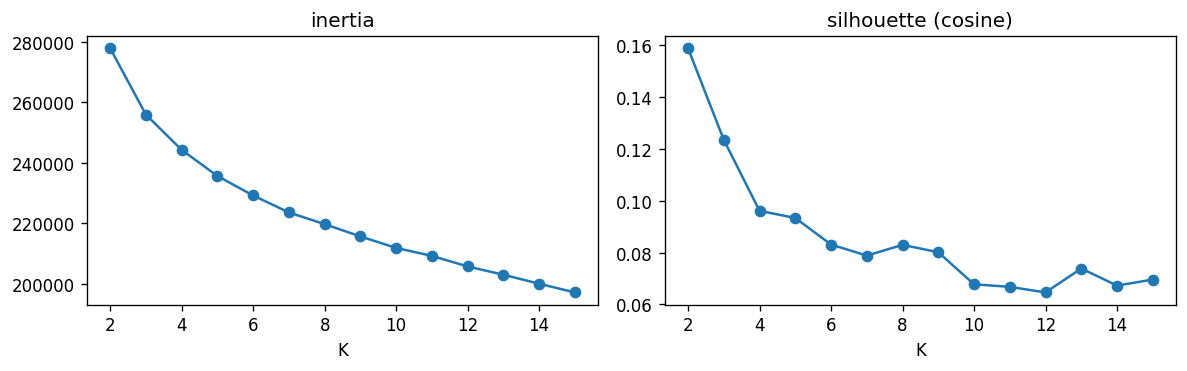

In [60]:
X = GAP_M
rng = np.random.default_rng(SEED)
sample = rng.choice(len(X), size=min(5000, len(X)), replace=False)

LABELS, quality = {}, []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
    # number clusters by size: 0 = largest
    order = {c: r for r, (c, _) in enumerate(Counter(km.labels_).most_common())}
    LABELS[k] = np.array([order[c] for c in km.labels_])
    quality.append(dict(K=k, inertia=km.inertia_,
                        silhouette=silhouette_score(X[sample], km.labels_[sample], metric="euclidean")))
quality = pd.DataFrame(quality).set_index("K")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), dpi=120)
quality["inertia"].plot(ax=axes[0], marker="o", title="inertia")
quality["silhouette"].plot(ax=axes[1], marker="o", title="silhouette (cosine)")
plt.tight_layout()
print(quality.round(3).T.to_string())

## Step 4 — the clustering at K, and whether it is stable
The same K from five random starts: an adjusted Rand index close to 1 means the clusters do not depend on the start.

In [72]:
K=8
CLUSTER = LABELS[K]
GAPS_DF["cluster"] = CLUSTER
print(GAPS_DF["cluster"].value_counts().sort_index().to_string())

runs = [KMeans(n_clusters=K, n_init=1, random_state=SEED + r).fit(X).labels_ for r in range(5)]
ari = [adjusted_rand_score(runs[a], runs[b]) for a in range(5) for b in range(a + 1, 5)]
print(f"\nadjusted Rand index between 5 single starts: mean {np.mean(ari):.2f}, min {np.min(ari):.2f}")

cluster
0    8173
1    6767
2    5608
3    5191
4    5159
5    3728
6    3705
7    2030

adjusted Rand index between 5 single starts: mean 0.53, min 0.34


## Step 5 — how much of each syntactic description do the clusters rebuild?
* **AMI** (adjusted mutual information): 0 = no more agreement than chance, 1 = the clusters and the descriptor are the same partition.
* **homogeneity**: does each cluster contain a single value of the descriptor?
* **completeness**: does each value of the descriptor fall in a single cluster?

Descriptors with many values (`between_in`, `flux_stack`) cannot be complete with only K clusters, so compare AMI first. The `words` family (word boundary or not, POS of the words) is a reference point, not a hypothesis. `combine()` builds a joint descriptor from two columns, for the "combination of criteria" question.

In [73]:
def agreement(labels, col):
    y = GAPS_DF[col].astype(str)
    h, c, _ = homogeneity_completeness_v_measure(y, labels)
    return dict(AMI=adjusted_mutual_info_score(y, labels), homogeneity=h, completeness=c,
                n_values=y.nunique())


def combine(a, b):
    name = f"{a} & {b}"
    GAPS_DF[name] = GAPS_DF[a].astype(str) + " & " + GAPS_DF[b].astype(str)
    return name


COMBINED = [combine("inside", "dep_inner_dir"), combine("between", "dep_inner"),
            combine("gap_type", "dep_inner_dir")]

table = pd.DataFrame([dict(family=fam, descriptor=col, **agreement(CLUSTER, col))
                      for fam, cols in {**DESCRIPTORS}.items() for col in cols])
print(table.sort_values("AMI", ascending=False).round(3).to_string(index=False))

      family    descriptor   AMI  homogeneity  completeness  n_values
       words      gap_type 0.131        0.270         0.087         2
constituency       between 0.127        0.111         0.181       388
       words      pos_pair 0.127        0.099         0.198       205
constituency    between_in 0.123        0.109         0.192       682
constituency        inside 0.116        0.115         0.119        23
constituency        n_open 0.100        0.136         0.079         5
  dependency     dep_inner 0.070        0.063         0.084        50
  dependency dep_inner_dir 0.062        0.092         0.047         3
       words     pos_after 0.061        0.058         0.065        14
  dependency    flux_stack 0.054        0.081         0.198      3534
constituency       n_close 0.053        0.082         0.039         5
       words    pos_before 0.052        0.049         0.056        14
  dependency      flux_dir 0.047        0.046         0.051        25
  dependency     flu

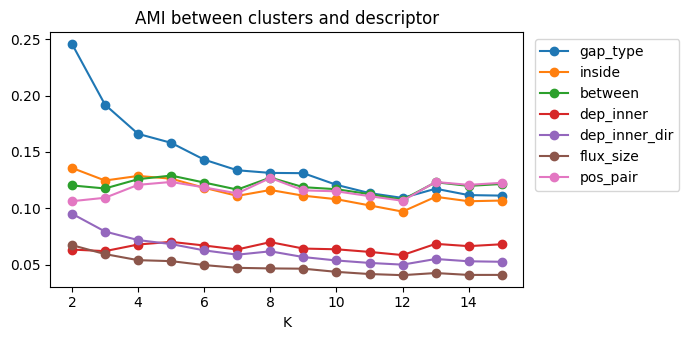

In [74]:
# AMI for every K: does a finer clustering rebuild more of each description?
show = ["gap_type", "inside", "between", "dep_inner", "dep_inner_dir", "flux_size", "pos_pair"]
ami_k = pd.DataFrame({col: [adjusted_mutual_info_score(GAPS_DF[col].astype(str), LABELS[k]) for k in K_RANGE]
                      for col in show}, index=list(K_RANGE))
ax = ami_k.plot(marker="o", figsize=(7, 3.5), title="AMI between clusters and descriptor")
ax.set_xlabel("K"); ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left"); plt.tight_layout()

## Step 6 — what each cluster contains, and where each syntactic value goes
`normalize_by="cluster"`: each row sums to 1 (the make-up of a cluster).
`normalize_by="value"`: each column sums to 1 (how one value spreads over the clusters).

inside       word         S        NP        VP        PP        N'        V'  \
cluster                                                                         
0        0.259854  0.143402  0.216530  0.207220  0.160943  0.116943  0.195307   
1        0.313929  0.051472  0.146630  0.064698  0.114086  0.062922  0.067288   
2        0.000000  0.192756  0.123179  0.272621  0.085856  0.410068  0.275017   
3        0.163417  0.143825  0.113843  0.091655  0.129220  0.062308  0.087992   
4        0.106396  0.218386  0.139344  0.053680  0.296275  0.039902  0.036232   
5        0.000000  0.076890  0.118852  0.211439  0.068102  0.235114  0.219807   
6        0.156403  0.053802  0.072860  0.049461  0.059953  0.027624  0.073844   
7        0.000000  0.119466  0.068761  0.049226  0.085565  0.045120  0.044513   

inside       AdvP        P'        CP        AP      Adv'  
cluster                                                    
0        0.140468  0.173432  0.112648  0.118072  0.082051  
1        

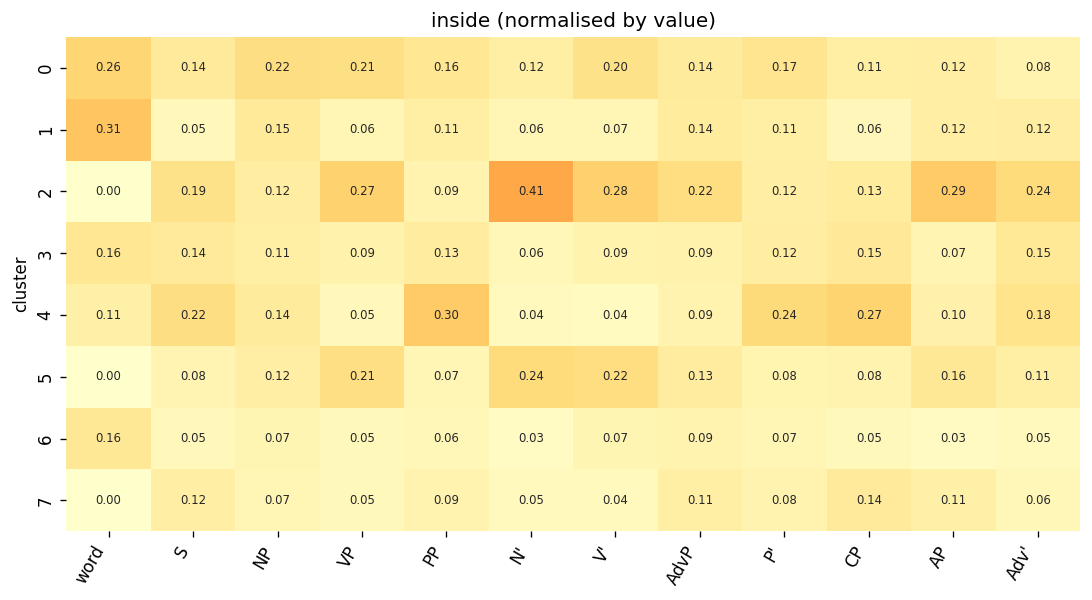

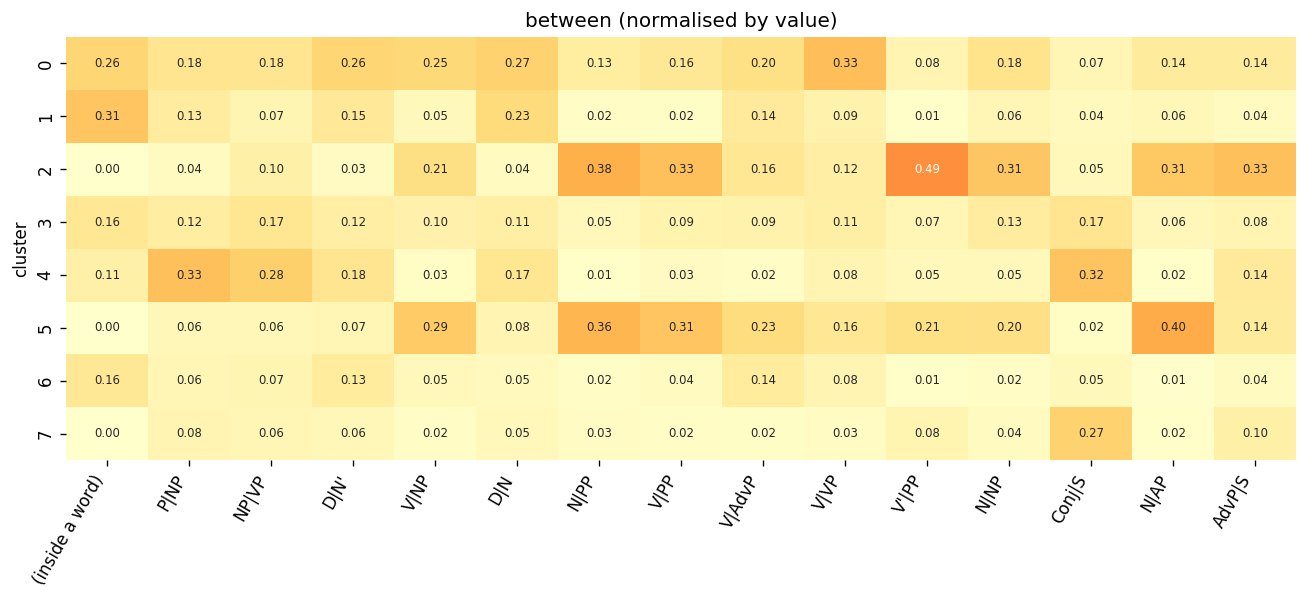

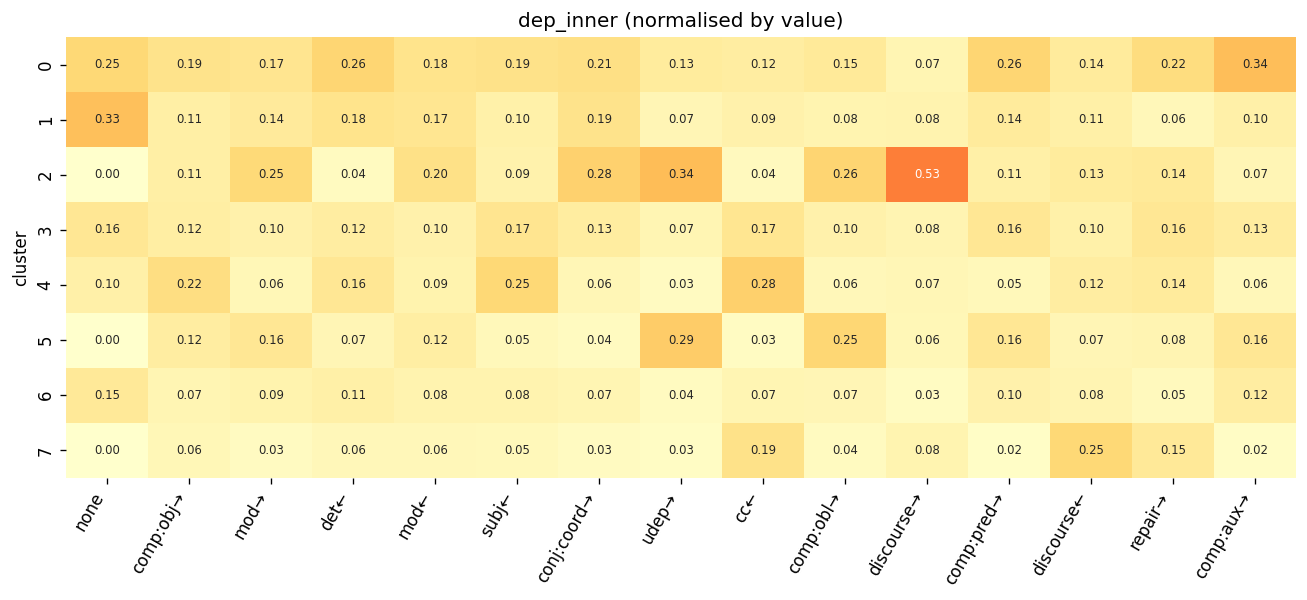

In [75]:
def crosstab(col, top=12, normalize_by="cluster", ax=None):
    vals = GAPS_DF[col].value_counts().index[:top]
    sub = GAPS_DF[GAPS_DF[col].isin(vals)]
    ct = pd.crosstab(sub["cluster"], sub[col]).reindex(columns=vals)
    ct = ct.div(ct.sum(axis=1), axis=0) if normalize_by == "cluster" else ct.div(ct.sum(axis=0), axis=1)
    print(ct)
    ax = ax or plt.subplots(figsize=(0.6 * len(vals) + 2, 0.45 * K + 1.5), dpi=120)[1]
    sns.heatmap(ct, annot=True, fmt=".2f", cmap="YlOrRd", vmin=0, vmax=1, cbar=False,
                annot_kws={"size": 7}, ax=ax)
    ax.set_title(f"{col} (normalised by {normalize_by})"); ax.set_xlabel("")
    plt.setp(ax.get_xticklabels(), rotation=60, ha="right")
    plt.tight_layout()
    return ct


crosstab("inside", normalize_by="value");
crosstab("between", top=15, normalize_by="value");
crosstab("dep_inner", top=15, normalize_by="value");

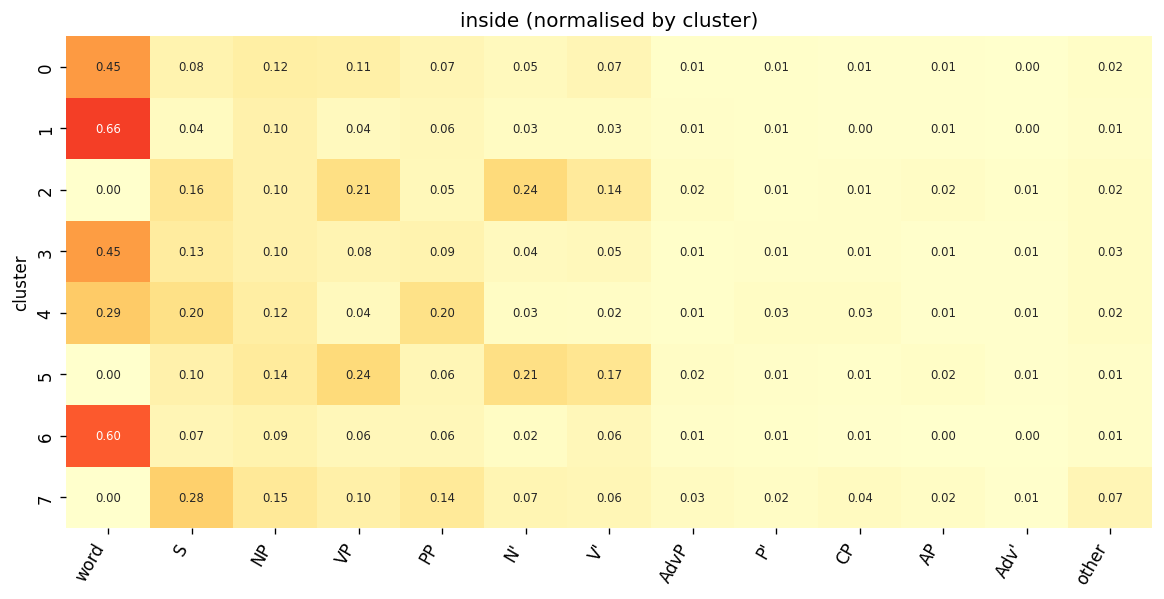

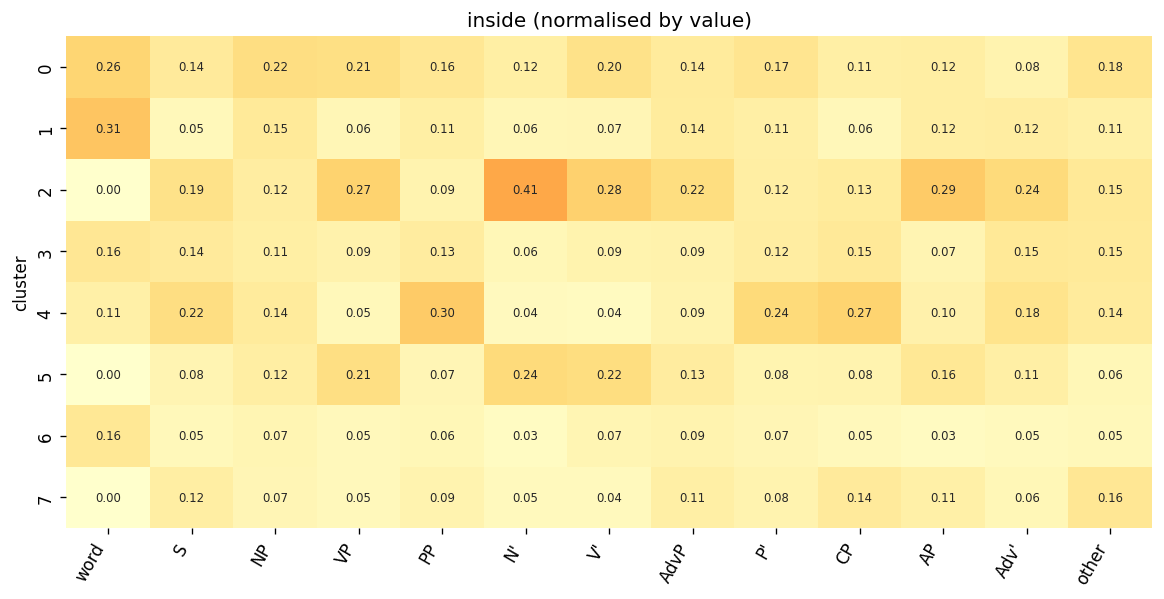

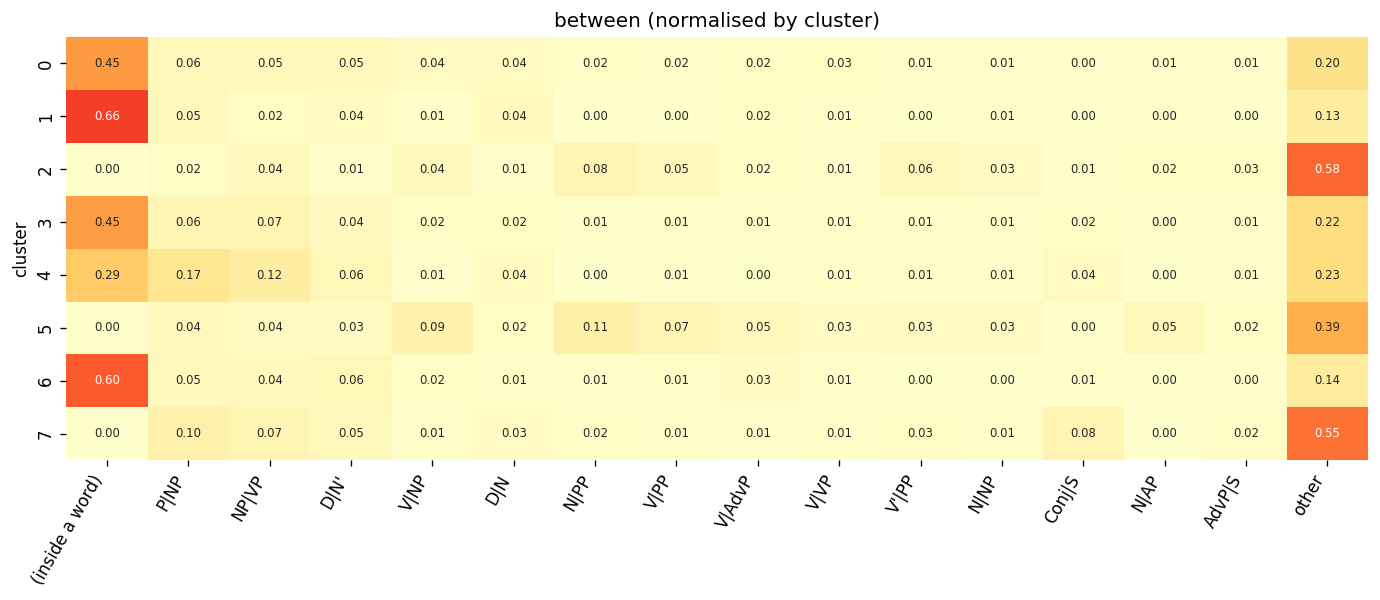

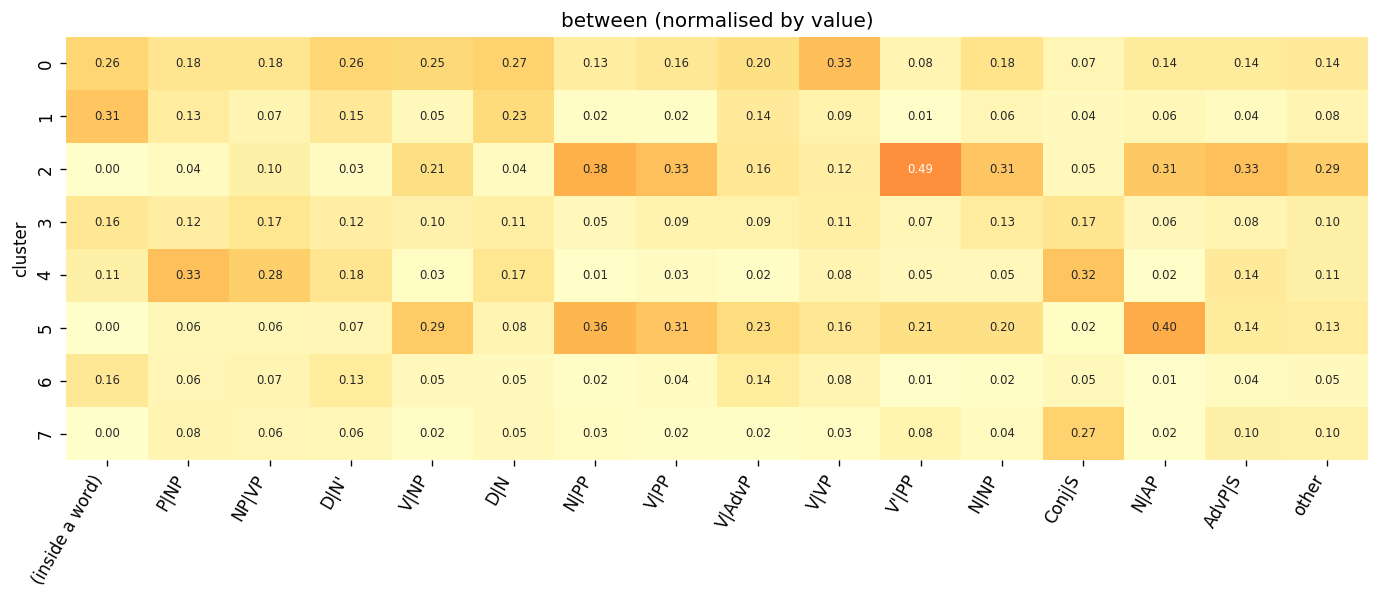

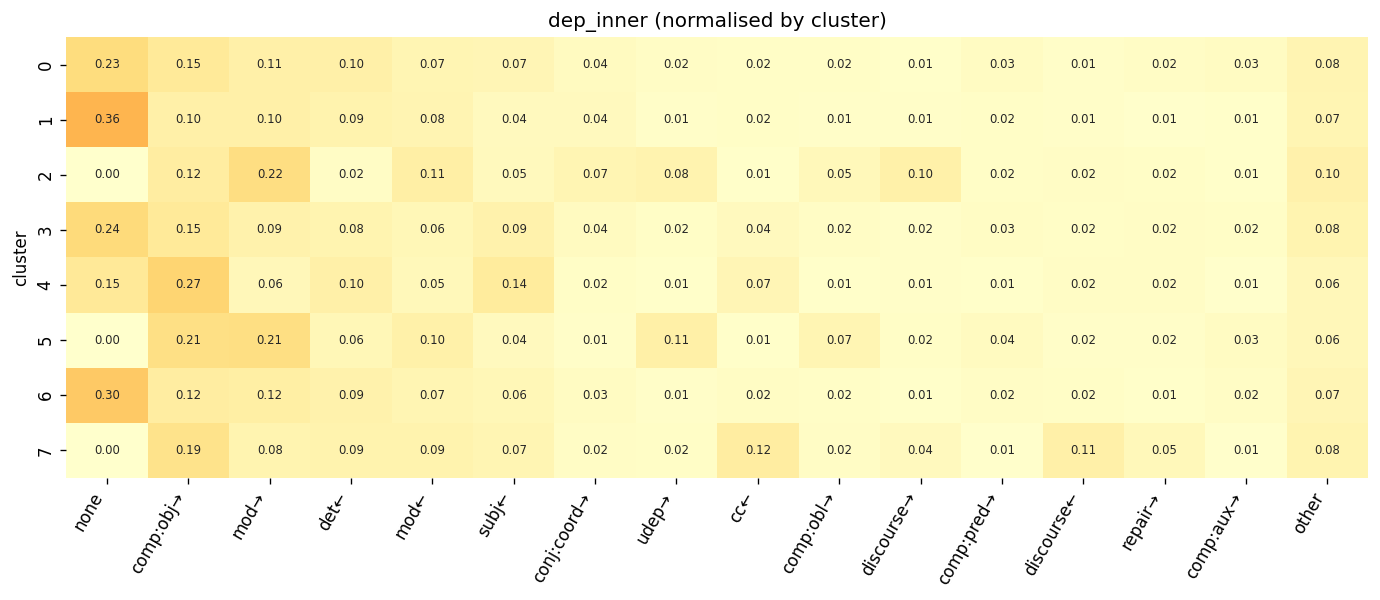

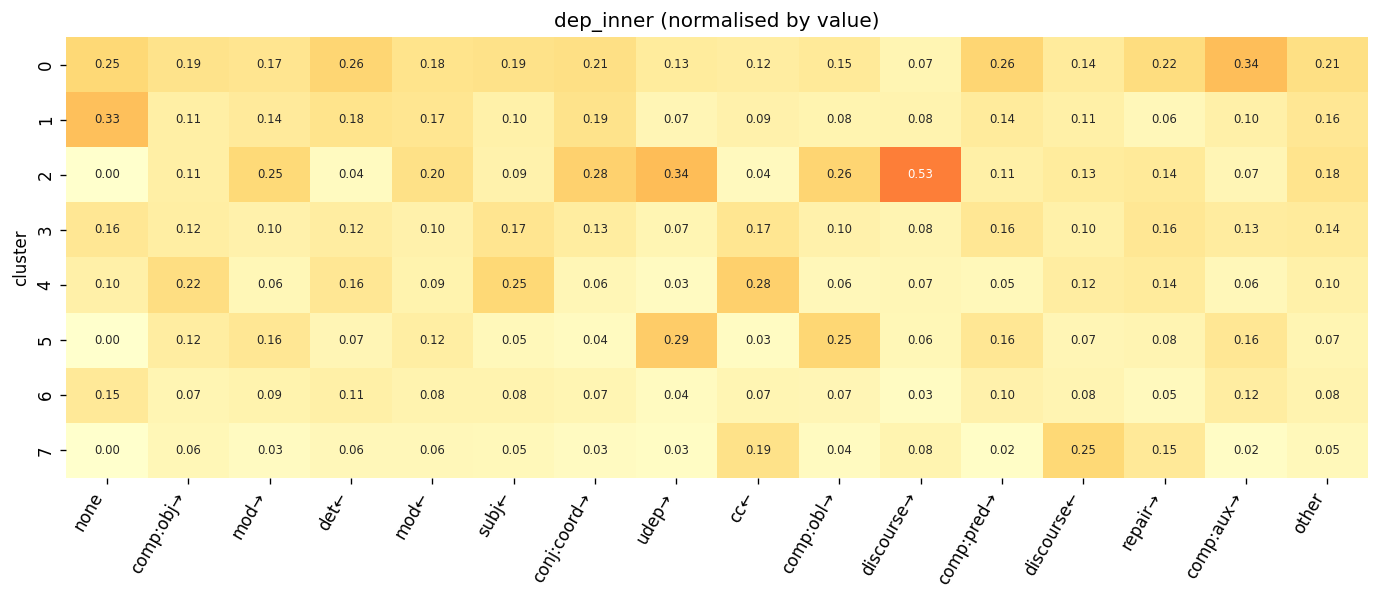

In [76]:
def crosstab(col, top=12, normalize_by="cluster", ax=None):
    vals = list(GAPS_DF[col].value_counts().index[:top])
    v = GAPS_DF[col].where(GAPS_DF[col].isin(vals), "other")
    ct = pd.crosstab(GAPS_DF["cluster"], v).reindex(columns=vals + ["other"], fill_value=0)
    ct = ct.div(ct.sum(axis=1), axis=0) if normalize_by == "cluster" else ct.div(ct.sum(axis=0), axis=1)
    ax = ax or plt.subplots(figsize=(0.6 * len(ct.columns) + 2, 0.45 * K + 1.5), dpi=120)[1]
    sns.heatmap(ct, annot=True, fmt=".2f", cmap="YlOrRd", vmin=0, vmax=1, cbar=False,
                annot_kws={"size": 7}, ax=ax)
    ax.set_title(f"{col} (normalised by {normalize_by})"); ax.set_xlabel("")
    plt.setp(ax.get_xticklabels(), rotation=60, ha="right")
    plt.tight_layout()
    return ct
 
 
for col, top in (("inside", 12), ("between", 15), ("dep_inner", 15)):
    crosstab(col, top, normalize_by="cluster")
    crosstab(col, top, normalize_by="value")

## Step 7 — cluster profiles
For each cluster:
* the prosodic features it is richest in, compared with all gaps (shown only when at least 10% of the cluster has them);
* the syntactic values it is richest in (shown only when at least 5% of the cluster has them);
* a few random examples.

In [77]:
PROFILE_COLS = ["gap_type", "inside", "between", "dep_inner", "flux_size", "pos_pair"]


def profile(c, n_feat=8, n_val=3, n_ex=6):
    sel = CLUSTER == c
    p_in, p_all = GAP_M[sel].mean(0), GAP_M.mean(0)
    lift = p_in / np.maximum(p_all, 1e-9)
    top = [j for j in np.argsort(-lift) if p_in[j] >= 0.10][:n_feat]
    print(f"\n━━ cluster {c}: {sel.sum()} gaps ({100 * sel.mean():.1f}%)")
    print("  prosody : " + "; ".join(f"{idx2feature[j]} {100 * p_in[j]:.0f}% (all {100 * p_all[j]:.0f}%)" for j in top))
    for col in PROFILE_COLS:
        share_in = GAPS_DF.loc[sel, col].value_counts(normalize=True)
        share_all = GAPS_DF[col].value_counts(normalize=True)
        best = (share_in[share_in >= 0.05] / share_all).dropna().sort_values(ascending=False).index[:n_val]
        print(f"  {col:9s}: " + "; ".join(f"{v} {100 * share_in[v]:.0f}% (all {100 * share_all[v]:.0f}%)" for v in best))
    for ex in GAPS_DF.loc[sel, "context"].sample(min(n_ex, sel.sum()), random_state=SEED):
        print("     ·", ex)


for c in range(K):
    profile(c)


━━ cluster 0: 8173 gaps (20.2%)
  prosody : before:Dur_short 51% (all 33%); before:SlopeGlo=Flat 94% (all 65%); after:Dur_short 43% (all 31%); before:F0_low 41% (all 30%); after:F0_low 38% (all 30%); before:PitchRangeGlo=L 100% (all 80%); before:AvgHeightGlo=M 92% (all 78%); after:SlopeGlo=Flat 76% (all 64%)
  gap_type : word-internal 45% (all 35%); word boundary 55% (all 65%)
  inside   : word 45% (all 35%); NP 12% (all 11%); VP 11% (all 11%)
  between  : (inside a word) 45% (all 35%); D|N' 5% (all 4%); P|NP 6% (all 7%)
  dep_inner: det← 10% (all 8%); none 23% (all 18%); subj← 7% (all 7%)
  flux_size: 0 23% (all 18%); 3 14% (all 13%); 4+ 8% (all 7%)
  pos_pair : NOUN 18% (all 13%); DET|NOUN 8% (all 6%); VERB 10% (all 8%)
     · contre je l' ai ‖ gardée la frange
     · par tout cet attirail[ta‖ti] de milliardaire
     · les autres dans les ‖ relations avec les uns
     · dès qu' il y ‖ avait quelque chose ça
     · je pense que aujourd'hui[o‖ZuR] euh s~ euh
     · mais vous ‖ étiez a

## Step 8 — which combination of syntactic criteria describes the clusters?
A shallow decision tree predicts each gap's cluster from its syntactic descriptors only. The cross-validated balanced accuracy (chance = 1/K) measures how much of the clustering one family explains, and how much the two together do. The rules of the combined tree are a first draft of a gap typology. Values seen fewer than 50 times are pooled as `other`.

In [78]:
def one_hot(cols, min_count=50):
    parts = []
    for col in cols:
        v = GAPS_DF[col].astype(str)
        v = v.where(v.map(v.value_counts()) >= min_count, "other")
        parts.append(pd.get_dummies(v, prefix=col, prefix_sep="=", dtype=np.uint8))
    return pd.concat(parts, axis=1)


def explain(cols, depth=TREE_DEPTH):
    Xd = one_hot(cols)
    tree = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=100,
                                  class_weight="balanced", random_state=SEED)
    pred = cross_val_predict(tree, Xd, CLUSTER, cv=StratifiedKFold(5, shuffle=True, random_state=SEED))
    return balanced_accuracy_score(CLUSTER, pred), tree.fit(Xd, CLUSTER), list(Xd.columns)


CONST = ["inside", "between", "n_close", "n_open"]
DEP = ["dep_inner", "dep_inner_dir", "flux_size", "flux_dir"]
WORDS = ["gap_type", "pos_before", "pos_after"]
families = {"constituency": CONST, "dependency": DEP, "words": WORDS,
            "constituency + dependency": CONST + DEP, "all three": CONST + DEP + WORDS}
trees = {}
for name, cols in families.items():
    acc, tree, names = explain(cols)
    trees[name] = (tree, names)
    print(f"{name:27s} balanced accuracy {100 * acc:5.1f}%   (chance {100 / K:.1f}%)")

constituency                balanced accuracy  27.7%   (chance 12.5%)
dependency                  balanced accuracy  22.7%   (chance 12.5%)
words                       balanced accuracy  29.0%   (chance 12.5%)
constituency + dependency   balanced accuracy  28.7%   (chance 12.5%)
all three                   balanced accuracy  29.0%   (chance 12.5%)


In [79]:
def rules(name):
    """The tree's rules, with 'x <= 0.50' written as 'not x'."""
    tree, names = trees[name]
    txt = export_text(tree, feature_names=names, class_names=[f"cluster {c}" for c in tree.classes_])
    txt = re.sub(r"--- (.+) <= 0\.50", r"--- not \1", txt)
    return re.sub(r"--- (.+) >  0\.50", r"--- \1", txt)


print(rules("constituency + dependency"))

|--- not inside=word
|   |--- not n_close=1
|   |   |--- not between=P|NP
|   |   |   |--- not n_close=0
|   |   |   |   |--- class: cluster 2
|   |   |   |--- n_close=0
|   |   |   |   |--- class: cluster 5
|   |   |--- between=P|NP
|   |   |   |--- not n_open=2
|   |   |   |   |--- class: cluster 4
|   |   |   |--- n_open=2
|   |   |   |   |--- class: cluster 4
|   |--- n_close=1
|   |   |--- not flux_dir=1←0→
|   |   |   |--- not dep_inner=mod←
|   |   |   |   |--- class: cluster 4
|   |   |   |--- dep_inner=mod←
|   |   |   |   |--- class: cluster 5
|   |   |--- flux_dir=1←0→
|   |   |   |--- not dep_inner=subj←
|   |   |   |   |--- class: cluster 7
|   |   |   |--- dep_inner=subj←
|   |   |   |   |--- class: cluster 4
|--- inside=word
|   |--- not dep_inner=det←
|   |   |--- not dep_inner=comp:aux→
|   |   |   |--- not dep_inner=comp:obj→
|   |   |   |   |--- class: cluster 1
|   |   |   |--- dep_inner=comp:obj→
|   |   |   |   |--- class: cluster 6
|   |   |--- dep_inner=comp:aux

In [80]:
# Save the gap table (descriptors + cluster) to look at it elsewhere
# GAPS_DF.to_csv("gaps_clusters.csv", index=False)